<a href="https://colab.research.google.com/github/RJC862/Titanic-Data/blob/main/rjc6651_Project_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔎 The Machine Learning Investigation
### Machine Learning Bootcamp · Classes 5 and 6

| | Class | You investigate | ⏱️ |
|:---|:---|:---|:---|
| 🩺🐧 **Part 1** | **5** · Supervised vs. unsupervised learning | a hospital and an Antarctic field station | ~35 min |
| 🧠🔢 **Part 2** | **6** · Neural networks | how neurons and layers learn, then 70,000 handwritten digits | ~40 min |

---
# 🧭 Part 1 · Supervised or unsupervised?

> 🎯 **By the end of Part 1 you will have:**
> - decided which type of learning two real problems need, and justified it
> - trained a classifier with scikit-learn and evaluated it on a test set
> - found clusters in unlabelled data and interpreted them

In [ ]:
#@title ⚙️ Setup · run this cell first { display-mode: "form" }
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, confusion_matrix
from ipywidgets import interact, FloatSlider, IntSlider, Checkbox
from IPython.display import display
try:
    from google.colab import output; output.enable_custom_widget_manager()
except ImportError:
    pass
pd.set_option('display.max_columns', None)

BLUE, INK, RED, ORANGE, GREY = "#2F6FE4", "#1C1A1D", "#D2342A", "#C96A00", "#8E888B"
STYLE = [(BLUE, "o"), (INK, "s"), (ORANGE, "^"), ("#1D5FD8", "D"), (GREY, "v"), ("#9A3B12", "P"), ("#12A594", "X"), ("#B54FD0", "*")]
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})

def check(passed, ok, fix):
    print(("✓ " + ok) if passed else ("✗ " + fix))
    return bool(passed)

def show_confusion(truth, guess, ax=None):
    cm = confusion_matrix(truth, guess, labels=["Malignant", "Benign"])
    ax = ax or plt.subplots(figsize=(4.8, 3.8))[1]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 18}, ax=ax,
                xticklabels=["Malignant", "Benign"], yticklabels=["Malignant", "Benign"])
    ax.set_xlabel("predicted"); ax.set_ylabel("actual")
    ax.set_title(f"Confusion matrix\nfalse negatives: {cm[0, 1]}  ·  false positives: {cm[1, 0]}")
    return cm

def scatter_clusters(ax, x, y, labels, title, names=None):
    for g in sorted(set(labels)):
        colour, marker = STYLE[g % len(STYLE)]
        m = labels == g
        ax.scatter(x[m], y[m], c=colour, marker=marker, s=40, alpha=.85, edgecolor="white", linewidth=.5,
                   label=names[g] if names else f"cluster {g}")
    ax.set_title(title); ax.legend(loc="upper left", fontsize=9)
    ax.set_xlabel("bill length (mm)"); ax.set_ylabel("flipper length (mm)")

def threshold_explorer(threshold=0.50):
    p_malignant = model.predict_proba(X_test_s)[:, list(model.classes_).index("Malignant")]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    show_confusion(y_test, np.where(p_malignant >= threshold, "Malignant", "Benign"), ax[0])
    ax[1].hist(p_malignant[y_test == "Malignant"], bins=25, alpha=.75, color=RED, label="actually malignant")
    ax[1].hist(p_malignant[y_test == "Benign"], bins=25, alpha=.75, color=BLUE, label="actually benign")
    ax[1].axvline(threshold, color=INK, lw=3, ls="--", label="threshold")
    ax[1].set_xlabel("predicted probability of malignant"); ax[1].set_ylabel("patients"); ax[1].legend()
    ax[1].set_title("Patients right of the threshold are predicted malignant")
    plt.tight_layout(); plt.show()

feature_trials = {}
def try_features(cols):
    Xa, Xb, ya, yb = train_test_split(hospital[cols], y, test_size=0.25, random_state=42, stratify=y)
    s = StandardScaler().fit(Xa)
    m = LogisticRegression(max_iter=5000).fit(s.transform(Xa), ya)
    feature_trials[", ".join(cols) if len(cols) < 4 else f"{len(cols)} features: {cols[0]}, …"] = accuracy_score(yb, m.predict(s.transform(Xb)))
    board = pd.Series(feature_trials).sort_values()
    ax = board.plot.barh(color=[BLUE if k == board.index[-1] else GREY for k in board.index], figsize=(8, 0.5 * len(board) + 1))
    ax.bar_label(ax.containers[0], labels=[f"{v:.0%}" for v in board], padding=4, fontweight="bold")
    plt.xlim(0.5, 1.05); plt.xlabel("test accuracy"); plt.title("Test accuracy by feature set (best in blue)"); plt.show()

def k_explorer(k=3, show_true_species=False):
    species = penguins_full["species"]
    lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_penguins).labels_
    fig, ax = plt.subplots(1, 2 if show_true_species else 1, figsize=(13 if show_true_species else 6.5, 4.6), squeeze=False)
    scatter_clusters(ax[0][0], penguins.bill_length_mm.values, penguins.flipper_length_mm.values, lab, f"K-Means with k = {k}")
    if show_true_species:
        scatter_clusters(ax[0][1], penguins.bill_length_mm.values, penguins.flipper_length_mm.values,
                         species.astype("category").cat.codes.values, "True species", list(species.astype("category").cat.categories))
    plt.tight_layout(); plt.show()
    if show_true_species:
        display(pd.crosstab(pd.Series(lab, name="cluster"), species.rename("species")))

print("✅ Part 1 ready")

✅ Part 1 ready


---
## 🩺 Case A · The hospital &nbsp;<sub>⏱️ ~15 min</sub>

| | |
|:---|:---|
| 📋 **Data** | 569 past patients · **30 measurements** of the cells in a breast-lump sample (size, shape, texture…) · the **diagnosis** later confirmed by biopsy |
| 🎯 **Request** | *"From the measurements alone, warn the doctor when a new lump is probably malignant."* |

### 💬 Q1 · Supervised or unsupervised?
Decide, and justify your choice with what you see above.

> Supervised because the lumps are labeled as malignant or benign.

,mean radius,mean texture,mean area,mean concavity,mean concave points,diagnosis
0,17.99,10.38,1001.0,0.3001,0.14710,Malignant
1,20.57,17.77,1326.0,0.0869,0.07017,Malignant
2,19.69,21.25,1203.0,0.1974,0.12790,Malignant
3,11.42,20.38,386.1,0.2414,0.10520,Malignant
4,20.29,14.34,1297.0,0.1980,0.10430,Malignant
5,12.45,15.70,477.1,0.1578,0.08089,Malignant


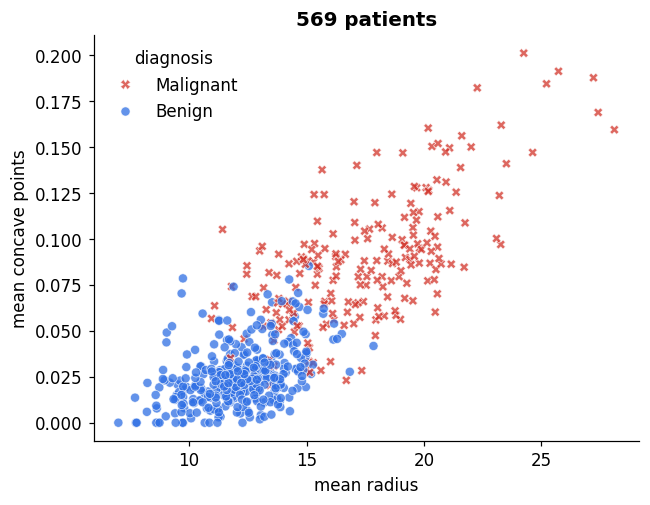

In [ ]:
# 🔍 Run · the first 6 patients (5 of the 30 measurements) and all 569 on one scatter plot
cancer = load_breast_cancer(as_frame=True)
hospital = cancer.frame.drop(columns="target").assign(diagnosis=cancer.target.map({0: "Malignant", 1: "Benign"}))
MEASUREMENTS = list(cancer.feature_names)

display(hospital[["mean radius", "mean texture", "mean area", "mean concavity", "mean concave points", "diagnosis"]].head(6))
sns.scatterplot(data=hospital, x="mean radius", y="mean concave points", hue="diagnosis", style="diagnosis",
                palette={"Malignant": RED, "Benign": BLUE}, markers={"Malignant": "X", "Benign": "o"}, alpha=.75)
plt.title("569 patients"); plt.show()

In [ ]:
hospital.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'diagnosis'],
      dtype='object')

### ✏️ Task A1 · Features and label
> 📖 The **features** `X` are what the model may look at. The **label** `y` is what it must learn to predict.

🧩 **Syntax** (the songs from class):
```python
X = songs[["energy", "danceability"]]   # a list of column names → a table of features
y = songs["liked"]                      # one column name → the label
```

In [ ]:
# the 30 measurement columns (hint: look at the cell above)
X = hospital[['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension'
      ]]
# the column the model must predict
y = hospital["diagnosis"]

check(X.shape == (569, 30), "X: 30 features for 569 patients", "X should be the 30 measurement columns")
check(getattr(y, "ndim", 0) == 1 and set(y) == {"Malignant", "Benign"}, "y: the label", "y should be one column: the one to predict")

# Given: 75% training set / 25% test set, then every feature standardised to the same scale.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print(f"training set: {len(X_train)} patients · test set: {len(X_test)} patients (never used for training)")

✓ X: 30 features for 569 patients
✓ y: the label
training set: 426 patients · test set: 143 patients (never used for training)


### ✏️ Task A2 · Train, then predict

🧩 **Syntax:**
```python
model.fit(training_features, training_labels)   # training: features AND labels
model.predict(new_features)                     # prediction: features only
```

✓ Test accuracy: 96.5%


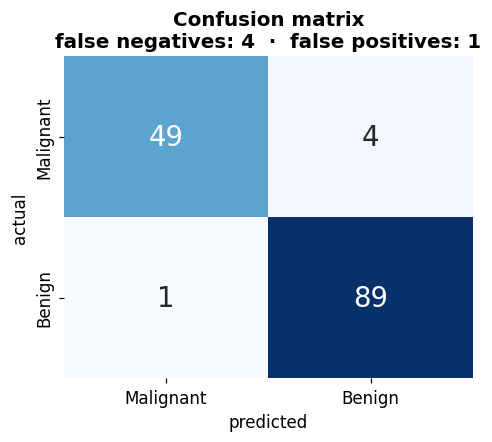

In [ ]:
model = LogisticRegression(max_iter=5000)

model.fit(X_train_s, y_train)

predictions = model.predict(X_test_s)

acc = accuracy_score(y_test, predictions)
check(acc > 0.9, f"Test accuracy: {acc:.1%}", "Accuracy too low: check what goes into fit and predict")
show_confusion(y_test, predictions); plt.show()

> 📖 **Confusion matrix:** rows = actual diagnosis, columns = prediction; the diagonal holds the correct predictions.
> - ❌ **False negative**: a malignant lump predicted *benign* (a missed cancer).
> - ⚠️ **False positive**: a benign lump predicted *malignant* (a false alarm).

### 🎛️ Explore · The decision threshold
The model outputs a **probability** of *Malignant*. The **decision threshold** turns it into a prediction: probability ≥ threshold → *Malignant*.

🤔 **Predict before you drag:** as the threshold goes down, what happens to false negatives? To false positives?

In [ ]:
interact(threshold_explorer, threshold=FloatSlider(value=0.01, min=0.02, max=0.98, step=0.02, continuous_update=False));

interactive(children=(FloatSlider(value=0.02, continuous_update=False, description='threshold', max=0.98, min=…

### 💬 Q2 · The threshold trade-off
Lower the threshold until no cancer is missed. What does that cost? Who should choose the threshold, and why?

> The model produces many false positives, but doesn't miss any cancer. Thus, the cost is accuracy, but all cancer is caught. This threshold should be chosen by someone who is able to characterize tumors as well, so that they can verify the model's predictions.

### 🧪 Experiment · Which features carry the answer?
A model can only learn from the features it gets. Train it on a **subset of the features**: edit `my_features`, run, and repeat with **at least 3 different lists** (one feature, two, all 30…). Each run is added to the chart.

💡 Feature names: `mean …`, `… error` or `worst …` + *radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension*.

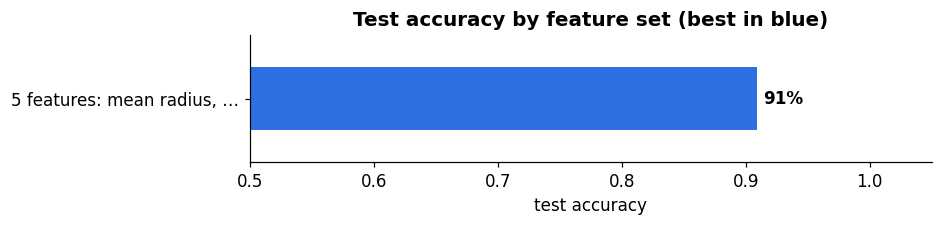

In [ ]:
my_features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', ]      # 🧪 edit, run, repeat
try_features(my_features)

### 💬 Q3 · Feature selection
Which single feature predicted best? How much did using all 30 add?

> mean radius predicted best on its own, and using all 30 boosted the accuracy to 97%.

---
## 🐧 Case B · The field station &nbsp;<sub>⏱️ ~15 min</sub>

| | |
|:---|:---|
| 📋 **Data** | 333 Antarctic penguins · **bill length, bill depth, flipper length, body mass**. The field notebook with each bird's species was lost on the way home. |
| 🎯 **Request** | *"How many natural groups of penguin are in here, and which bird belongs to which?"* |

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
3,36.7,19.3,193.0,3450.0


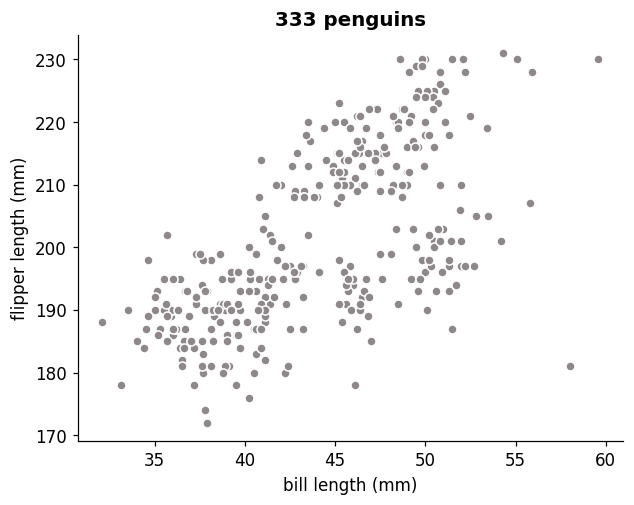

In [ ]:
# 🔍 Run · the surviving measurements (downloads from GitHub: needs internet)
penguins_full = sns.load_dataset("penguins").dropna().reset_index(drop=True)
penguins = penguins_full[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]

display(penguins.head(4))
plt.scatter(penguins.bill_length_mm, penguins.flipper_length_mm, c=GREY, s=35, edgecolor="white")
plt.xlabel("bill length (mm)"); plt.ylabel("flipper length (mm)"); plt.title("333 penguins"); plt.show()

### 💬 Q4 · Supervised or unsupervised?
Decide, and justify your choice.

> Unsupervised since the data points are not labeled by category.

### 📈 Choosing k · the elbow method
> 📖 **K-Means** splits the data into *k* **clusters**, each around a **centroid** (the cluster's mean point). You choose *k*.
>
> 📖 **Inertia** = the sum of squared distances from every point to its centroid: lower means tighter clusters. Adding clusters always lowers it, so the lowest value is not the goal.
>
> 📖 **Elbow method:** plot inertia for k = 1, 2, 3… and pick the k where the curve stops falling steeply.

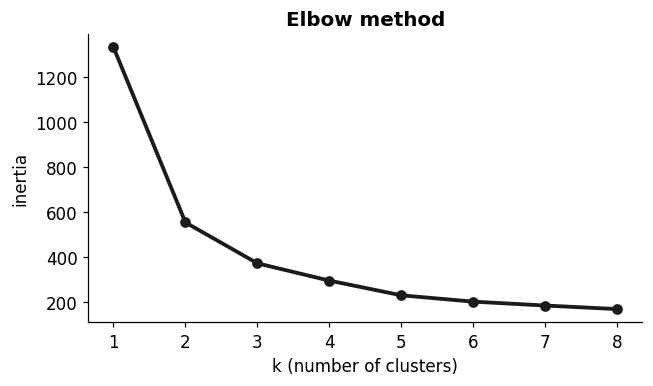

In [ ]:
# 🔍 Run · standardise the 4 features (only X: there is no y), then inertia for k = 1…8
X_penguins = StandardScaler().fit_transform(penguins)
inertia = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_penguins).inertia_ for k in range(1, 9)]
plt.figure(figsize=(6.5, 3.4)); plt.plot(range(1, 9), inertia, "o-", color=INK, lw=2.5)
plt.xlabel("k (number of clusters)"); plt.ylabel("inertia"); plt.title("Elbow method"); plt.show()

### ✏️ Task B1 · Cluster the penguins

🧩 **Syntax:**
```python
kmeans = KMeans(n_clusters=4)
labels = kmeans.fit_predict(song_features)   # fits the clusters AND returns each row's cluster label (X only, no y)
```

✓ All 333 penguins assigned to 3 clusters


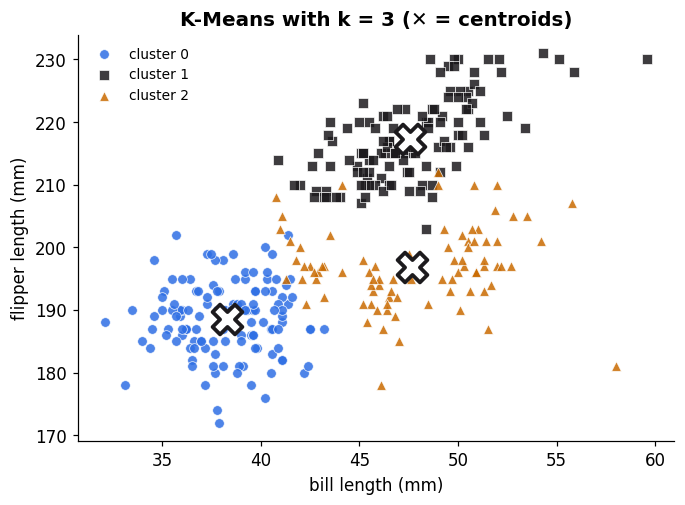

Mean measurements of each cluster:


,bill length (mm),bill depth (mm),flipper length (mm),body mass (g)
cluster,,,,
0,38,18,189,3594
1,48,15,217,5092
2,48,19,197,3898


In [ ]:
# your k, read from the elbow plot
K = 3
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
# fit the clusters and get each penguin's cluster label
clusters = kmeans.fit_predict(X_penguins)

check(len(clusters) == 333, f"All 333 penguins assigned to {K} clusters", "clusters needs one cluster label per penguin")
centroids = kmeans.cluster_centers_ * penguins.std(ddof=0).values + penguins.mean().values
fig, ax = plt.subplots(figsize=(7, 4.8))
scatter_clusters(ax, penguins.bill_length_mm.values, penguins.flipper_length_mm.values, clusters, f"K-Means with k = {K} (✕ = centroids)")
ax.scatter(centroids[:, 0], centroids[:, 2], marker="X", s=380, c="white", edgecolor=INK, linewidth=2.5, zorder=5)
plt.show()
print("Mean measurements of each cluster:")
display(penguins.assign(cluster=clusters).groupby("cluster").mean().round(0).astype(int)
        .rename(columns={"bill_length_mm": "bill length (mm)", "bill_depth_mm": "bill depth (mm)", "flipper_length_mm": "flipper length (mm)", "body_mass_g": "body mass (g)"}))

### 💬 Q5 · Name the clusters
K-Means returns numbers, not names. Describe each cluster in a few words, using the table of means.

> Cluster 0 has shorter beak lengths with average bill depth. Flipper lengths are also short and body mass is very low.
Cluster 1 has average beak length with low bill depths and long flippers. Very high body mass.
Cluster 2 has average beak length with high bill depths and average flipper length. Average body mass

### 🎛️ Explore · Change k, then reveal the true species
This is a public dataset, so the species are actually known. K-Means never saw them. Choose a k first, **then** tick *show true species*.

In [ ]:
interact(k_explorer, k=IntSlider(value=3, min=2, max=8, continuous_update=False), show_true_species=Checkbox(value=False));

interactive(children=(IntSlider(value=3, continuous_update=False, description='k', max=8, min=2), Checkbox(val…

### 💬 Q6 · Who judges the clusters?
Try k = 6. Then compare k = 3 with the true species. What does K-Means get wrong, and who has to notice?

> K-means mistakes gentoo for chinstrap, and this data would have to be caught by someone who is knowledgable about penguins.

---
## ✅ End of Part 1

| | 🩺 Hospital | 🐧 Field station |
|:---|:---|:---|
| Labels? | `diagnosis` ✔ | lost ✘ |
| Learning | supervised · `fit(X, y)` | unsupervised · `fit_predict(X)` |
| Output | a prediction you can **evaluate** (accuracy) | cluster labels you must **interpret** |

▶️ Run the check. When every line shows ✓ it prints the **first half** of your code phrase.

In [ ]:
#@title ✅ Check Part 1 { display-mode: "form" }
import base64
part1 = all([
    check("X" in globals() and getattr(X, "shape", None) == (569, 30), "A1: X = the 30 features", "A1: finish Task A1"),
    check("y" in globals() and set(y) == {"Malignant", "Benign"}, "A1: y = the diagnosis", "A1: y should be the label column"),
    check("predictions" in globals() and accuracy_score(y_test, predictions) > 0.9, "A2: model trained and evaluated", "A2: finish Task A2"),
    check(len(globals().get("feature_trials", {})) >= 3, "Experiment: 3+ feature sets tried", "Experiment: try at least 3 different feature lists"),
    check("clusters" in globals() and len(clusters) == 333, "B1: every penguin has a cluster", "B1: finish Task B1"),
    # an elbow: a big drop going TO k (over 10% of the inertia at k = 1), more than twice the drop going past it
    check("K" in globals() and 2 <= K <= 7 and (inertia[K - 2] - inertia[K - 1]) > max(2 * (inertia[K - 1] - inertia[K]), 0.1 * inertia[0]),
          "B1: k chosen at the elbow", "B1: look at the elbow plot again"),
])
print()
print("🔑 PART 1 CODE PHRASE:  " + base64.b64decode("TGFiZWxzIGRlY2lkZSB3aGF0IHlvdSBjYW4gYXNrOw==").decode() if part1 else "Fix the ✗ lines above, then run this cell again.")

✓ A1: X = the 30 features
✓ A1: y = the diagnosis
✓ A2: model trained and evaluated
✗ Experiment: try at least 3 different feature lists
✓ B1: every penguin has a cluster
✓ B1: k chosen at the elbow

Fix the ✗ lines above, then run this cell again.


> 🛑 **Stop here at the end of Class 5.** Save your work (**File → Save a copy in Drive**). Part 2 starts with its own setup cell.
>
> 🔮 **Next class:** today a person chose the features (cell size, bill length). A photo has no such columns, only pixels. *What if the model learned the features itself?*

---
# 🧠 Part 2 · Neural networks, from one neuron to reading digits

> 🎯 **By the end of Part 2 you will have:**
> - coded a single neuron yourself and seen what its weights, bias and activation function do
> - built networks of different sizes and watched hidden neurons combine lines into shapes
> - built, trained and inspected a network that reads handwritten digits
> - tuned its hyperparameters and caught it overfitting

| 🔁 From Class 5 | 🆕 From Class 6 |
|:---|:---|
| features **X**, labels **y** | a neuron: inputs × **weights** + **bias** → **activation function** |
| supervised learning · `fit(X, y)` | a **network** = layers of neurons; weights and biases are its **parameters** |
| evaluate on a **test set** | training: predict → **loss** → update parameters · too long → **overfitting** |

In [ ]:
#@title ⚙️ Setup · run this cell first (Colab forgets Part 1 between classes; downloads MNIST, ~11 MB) { display-mode: "form" }
import os, warnings; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"; warnings.filterwarnings("ignore")
import base64, numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
from IPython.display import display, Markdown
from ipywidgets import interact, IntSlider, Checkbox, Dropdown, SelectionSlider
from sklearn.datasets import make_circles
from tensorflow import keras
from tensorflow.keras import layers
try:
    from google.colab import output; output.enable_custom_widget_manager()
except ImportError:
    pass

BLUE, INK, RED, GREY = "#2F6FE4", "#1C1A1D", "#D2342A", "#8E888B"
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
keras.utils.set_random_seed(42)

def check(passed, ok, fix):
    print(("✓ " + ok) if passed else ("✗ " + fix))
    return bool(passed)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# ---------- 2.1 · the umbrella neuron
WEATHER = {"☁️ cloudy, humid, calm": [0.8, 0.7, 0.3], "☀️ clear and dry": [0.1, 0.2, 0.2], "⛈️ cloudy and stormy": [0.9, 0.8, 0.9]}
INPUT_NAMES = ["cloud cover", "humidity", "wind"]

def neuron_explorer(day="☁️ cloudy, humid, calm", w_clouds=5, w_humidity=2, w_wind=1, bias=-4):
    x, w = np.array(WEATHER[day]), np.array([w_clouds, w_humidity, w_wind], dtype=float)
    out = float(neuron(x, w, bias))                # your neuron from Task 2.1
    z = float(np.log(np.clip(out, 1e-9, 1 - 1e-9) / (1 - np.clip(out, 1e-9, 1 - 1e-9))))   # recover z from the output, to place it on the curve
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1.6, 1.3, 0.7]})
    parts = list(x * w) + [bias]
    names = [f"{n}\n{v:g} × {wt:g}" for n, v, wt in zip(INPUT_NAMES, x, w)] + ["bias"]
    ax[0].barh(names, parts, color=[BLUE if p >= 0 else RED for p in parts]); ax[0].axvline(0, color=INK, lw=1)
    ax[0].invert_yaxis(); ax[0].set_title(f"weighted inputs + bias  =  z = {z:.2f}")
    t = np.linspace(-8, 8, 200)
    ax[1].plot(t, sigmoid(t), color=RED, lw=3); ax[1].plot(np.clip(z, -8, 8), out, "o", ms=14, color=BLUE, mec=INK)
    ax[1].axhline(0.5, color=GREY, ls="--", lw=1); ax[1].set_xlabel("z"); ax[1].set_title("sigmoid activation")
    ax[2].bar([0], [out], color=BLUE if out >= 0.5 else GREY, width=0.6); ax[2].axhline(0.5, color=INK, ls="--")
    ax[2].set_ylim(0, 1); ax[2].set_xticks([]); ax[2].set_title(f"output {out:.2f}\n{'→ umbrella' if out >= 0.5 else '→ no umbrella'}")
    plt.tight_layout(); plt.show()

# ---------- 2.2 · networks on a 2-D problem (inner blob vs outer ring)
RING_X, RING_Y = make_circles(n_samples=400, factor=0.35, noise=0.12, random_state=0)
RING_X = (RING_X * 3).astype("float32"); RING_Y = RING_Y.astype("float32").reshape(-1, 1)
_toy_cache = {}

def train_toy(net, steps=300):
    opt, loss_fn = keras.optimizers.Adam(0.05), keras.losses.BinaryCrossentropy()
    Xt, yt = tf.constant(RING_X), tf.constant(RING_Y)
    @tf.function
    def step():
        with tf.GradientTape() as tape:
            loss = loss_fn(yt, net(Xt, training=True))
        grads = tape.gradient(loss, net.trainable_variables)
        opt.apply_gradients(zip(grads, net.trainable_variables))
    for _ in range(steps): step()
    return float(((net(Xt).numpy() > .5) == (RING_Y > .5)).mean())

def toy_network(hidden):
    # best of 3 random starts, like the Playground's reset button
    if hidden not in _toy_cache:
        best = (-1, None)
        for seed in range(3):
            keras.utils.set_random_seed(seed)
            net = build_network(2, hidden, 1, "sigmoid") if hidden else keras.Sequential([layers.Input(shape=(2,)), layers.Dense(1, activation="sigmoid")])
            acc = train_toy(net)
            if acc > best[0]: best = (acc, net)
        _toy_cache[hidden] = best
    return _toy_cache[hidden]

def boundary_explorer(hidden_neurons=1, show_each_neuron=False):
    acc, net = toy_network(hidden_neurons)
    xx, yy = np.meshgrid(np.linspace(-4.5, 4.5, 250), np.linspace(-4.5, 4.5, 250))
    zz = net(np.c_[xx.ravel(), yy.ravel()].astype("float32")).numpy().reshape(xx.shape)
    fig, ax = plt.subplots(figsize=(6.2, 6))
    ax.contourf(xx, yy, zz, levels=[0, .5, 1], colors=["#F1EEEC", "#D6E4FB"])
    ax.contour(xx, yy, zz, levels=[.5], colors=[RED], linewidths=3)
    inner = RING_Y.ravel() == 1
    ax.scatter(*RING_X[inner].T, c=BLUE, s=22, label="inner blob"); ax.scatter(*RING_X[~inner].T, facecolors="white", edgecolors=INK, s=22, label="outer ring")
    if show_each_neuron and hidden_neurons:
        W, b = net.layers[0].get_weights()
        t = np.linspace(-4.5, 4.5, 2)
        for k in range(hidden_neurons):   # each hidden neuron switches on along one straight line: w1·x1 + w2·x2 + b = 0
            if abs(W[1, k]) > 1e-6: ax.plot(t, -(W[0, k] * t + b[k]) / W[1, k], color=INK, ls="--", lw=1.5)
            else: ax.axvline(-b[k] / W[0, k], color=INK, ls="--", lw=1.5)
    ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5); ax.set_xlabel("x₁"); ax.set_ylabel("x₂"); ax.legend(loc="upper right", fontsize=9)
    ax.set_title(f"{hidden_neurons} hidden neuron{'s' if hidden_neurons != 1 else ''} · accuracy {acc:.0%}\n(red = decision boundary)")
    plt.show()

# ---------- 2.4 · drawing the network
def draw_network(spec):
    # spec: a list of layer sizes, or a Keras model (then each layer shows the code that created it).
    if isinstance(spec, keras.Model):
        dense = [l for l in spec.layers if isinstance(l, layers.Dense)]
        sizes = [spec.input_shape[-1]] + [l.units for l in dense]
        code = [f"Input(shape=({sizes[0]},))"] + [f'Dense({l.units}, "{l.activation.__name__}")' for l in dense]
    else:
        sizes, code = spec, None
    fig, ax = plt.subplots(figsize=(2.8 * len(sizes) + 1, 4.4))
    xs = np.arange(len(sizes)) * 3
    pos = [np.linspace(3, -3, n) if n <= 8 else np.r_[np.linspace(3, 1, 4), np.linspace(-1, -3, 4)] for n in sizes]
    for i in range(len(sizes) - 1):
        for a in pos[i]:
            for b in pos[i + 1]:
                ax.plot([xs[i], xs[i + 1]], [a, b], color="#C9C5C7", lw=.6, zorder=1)
    for i, n in enumerate(sizes):
        ax.scatter([xs[i]] * len(pos[i]), pos[i], s=260, color=BLUE, edgecolor=INK, linewidth=1.8, zorder=2)
        if n > 8: ax.text(xs[i], 0, "⋮", ha="center", va="center", fontsize=24, zorder=3, bbox=dict(fc="white", ec="none", pad=6))
        role = "input layer" if i == 0 else ("output layer" if i == len(sizes) - 1 else "hidden layer")
        ax.text(xs[i], -4.1, f"{n}\n{role}", ha="center", va="top", fontsize=13, fontweight="bold")
        if code: ax.text(xs[i], 4.0, code[i], ha="center", fontsize=9.5, family="monospace", color="#1D5FD8")
    ax.set_xlim(-1.5, xs[-1] + 1.5); ax.set_ylim(-6, 4.8); ax.axis("off"); plt.show()

# ---------- 2.5 / 2.7 · training curves, redrawn after every epoch
class LiveCurves(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.h, self.handle = {}, display(Markdown("⏳ first epoch…"), display_id=True)
    def on_epoch_end(self, epoch, logs=None):
        for k, v in logs.items(): self.h.setdefault(k, []).append(v)
        ep = range(1, epoch + 2)
        fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
        for a, key, title in [(ax[0], "loss", "Loss (lower is better)"), (ax[1], "accuracy", "Accuracy (higher is better)")]:
            a.plot(ep, self.h[key], "o-", color=INK, lw=2.5, label="training set")
            a.plot(ep, self.h["val_" + key], "s--", color=BLUE, lw=2.5, label="validation set")
            a.set_title(title); a.set_xlabel("epoch"); a.xaxis.set_major_locator(plt.MaxNLocator(10, integer=True))
        gap = self.h["accuracy"][-1] - self.h["val_accuracy"][-1]
        if gap > 0.02:   # mark the generalization gap at the last epoch
            ax[1].annotate("", (epoch + 1, self.h["val_accuracy"][-1]), (epoch + 1, self.h["accuracy"][-1]), arrowprops=dict(arrowstyle="<->", color=RED, lw=2))
            ax[1].text(epoch + 0.7, (self.h["accuracy"][-1] + self.h["val_accuracy"][-1]) / 2, f"gap {gap * 100:.0f} pts", color=RED, ha="right", va="center", fontweight="bold")
        best = int(np.argmin(self.h["val_loss"])) + 1
        if best <= epoch - 2 and self.h["val_loss"][-1] > 1.10 * min(self.h["val_loss"]):   # clearly rising after its minimum, not noise
            ax[0].axvspan(best, epoch + 1, color=RED, alpha=.1)
            ax[0].text(0.98, 0.95, f"overfitting: validation loss rising since epoch {best}", transform=ax[0].transAxes, color=RED, ha="right", va="top", fontweight="bold",
                       bbox=dict(fc="white", ec="none", pad=2))
            ax[0].plot(best, self.h["val_loss"][best - 1], "o", ms=13, mfc="none", mec=RED, mew=3)
        fig.legend(*ax[0].get_legend_handles_labels(), loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.08))
        plt.tight_layout(); self.handle.update(fig); plt.close(fig)

# ---------- 2.3 · pixels
def pixel_explorer(index=0):
    img = X_train_img[index]
    fig, ax = plt.subplots(1, 2, figsize=(12, 5.4), gridspec_kw={"width_ratios": [1, 1.5]})
    ax[0].imshow(img, cmap="gray_r"); ax[0].set_title(f"label: {y_train[index]}"); ax[0].axis("off")
    ax[0].add_patch(plt.Rectangle((7.5, 5.5), 12, 10, fill=False, color=RED, lw=3))
    patch = img[6:16, 8:20]
    ax[1].imshow(patch, cmap="gray_r", vmin=0, vmax=255); ax[1].axis("off"); ax[1].set_title("pixel values inside the red box")
    for i in range(patch.shape[0]):
        for j in range(patch.shape[1]):
            ax[1].text(j, i, patch[i, j], ha="center", va="center", fontsize=10, color="white" if patch[i, j] > 120 else "#6F696C")
    plt.tight_layout(); plt.show()

# ---------- 2.6 · predictions
def prediction_explorer(n=0, errors_only=False):
    i = wrong[n % len(wrong)] if errors_only else n
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1, 2.2]})
    ax[0].imshow(X_test_img[i], cmap="gray_r"); ax[0].axis("off")
    ax[0].set_title(f"label {y_test[i]} · predicted {guess[i]}", color=INK if guess[i] == y_test[i] else RED)
    ax[1].bar(range(10), probs[i], color=[BLUE if d == y_test[i] else (RED if d == guess[i] else GREY) for d in range(10)])
    ax[1].set_xticks(range(10)); ax[1].set_ylim(0, 1); ax[1].set_xlabel("digit"); ax[1].set_ylabel("probability")
    ax[1].set_title("output probabilities (blue = true label, red = wrong prediction)")
    plt.tight_layout(); plt.show()

# ---------- 2.7 · hyperparameter runs
lab_runs = []
def lab_run(hidden, epochs, images):
    keras.utils.set_random_seed(42)
    out_activation = model.layers[-1].get_config()["activation"]        # the output activation you chose in Task 2.4
    net = build_network(784, hidden, 10, out_activation) if hidden else keras.Sequential([layers.Input(shape=(784,)), layers.Dense(10, activation=out_activation)])
    net.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = net.fit(X_train[:images], y_train[:images], validation_data=(X_train[50000:55000], y_train[50000:55000]),
                epochs=epochs, batch_size=32, callbacks=[LiveCurves()], verbose=0).history
    lab_runs.append({"run": len(lab_runs) + 1, "hidden": hidden, "epochs": epochs, "images": images,
                     "training": h["accuracy"][-1], "validation": h["val_accuracy"][-1]})
    show_runs()

def show_runs():
    runs = pd.DataFrame(lab_runs); x = np.arange(len(runs))
    fig, ax = plt.subplots(figsize=(11, 4.2))
    tr = ax.bar(x - 0.2, runs["training"], 0.4, color=INK, label="training accuracy")
    va = ax.bar(x + 0.2, runs["validation"], 0.4, color=BLUE, label="validation accuracy")
    ax.bar_label(tr, labels=[f"{v:.1%}" for v in runs["training"]], padding=2, fontsize=9)
    ax.bar_label(va, labels=[f"{v:.1%}" for v in runs["validation"]], padding=2, fontsize=9, fontweight="bold", color="#1D5FD8")
    for i, (t, v) in enumerate(zip(runs["training"], runs["validation"])):
        ax.text(i, 0.815, f"gap {(t - v) * 100:.0f} pts", ha="center", color=RED if t - v > 0.06 else INK, fontweight="bold", fontsize=10, bbox=dict(fc="white", ec="none", pad=1))
    ax.set_xticks(x, [f"run {r['run']}\n{r['hidden']} hidden · {r['epochs']} epochs\n{r['images']:,} images" for r in lab_runs], fontsize=10)
    ax.set_xlim(-0.6, max(4.6, len(runs) - 0.4)); ax.set_ylim(0.8, 1.04); ax.set_ylabel("accuracy"); ax.legend(loc="upper left", ncol=2)
    ax.set_title("All runs so far"); plt.tight_layout(); plt.show()

# ---------- 2.8 · shifted digits
_shift_cache = {}
def shift_accuracy():
    # test accuracy after shifting every test image 0–6 pixels to the right (computed once per trained model)
    if id(model) not in _shift_cache:
        _shift_cache[id(model)] = {s: (model.predict(to_rows(np.roll(X_test_img, s, axis=2)), verbose=0).argmax(1) == y_test).mean() for s in range(7)}
    return _shift_cache[id(model)]

def shift_explorer(index=0, pixels=3):
    img = np.roll(X_test_img[index], pixels, axis=1)
    p = model.predict(to_rows(img[None]), verbose=0)[0]
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.4), gridspec_kw={"width_ratios": [1, 1.6, 1.8]})
    ax[0].imshow(img, cmap="gray_r"); ax[0].axis("off"); ax[0].set_title(f"shifted {pixels} px → predicted {p.argmax()}")
    ax[1].bar(range(10), p, color=[BLUE if d == y_test[index] else GREY for d in range(10)]); ax[1].set_xticks(range(10)); ax[1].set_ylim(0, 1)
    ax[1].set_title(f"output probabilities (blue = true label {y_test[index]})")
    shift_acc = shift_accuracy()
    ax[2].plot(list(shift_acc), list(shift_acc.values()), "o-", color=GREY); ax[2].plot(pixels, shift_acc[pixels], "o", ms=14, color=RED)
    ax[2].set_ylim(0, 1); ax[2].set_xlabel("pixels shifted"); ax[2].set_ylabel("test accuracy")
    ax[2].set_title(f"all 10,000 test images: {shift_acc[pixels]:.0%}")
    plt.tight_layout(); plt.show()

(X_train_img, y_train), (X_test_img, y_test) = keras.datasets.mnist.load_data()
print("✅ Part 2 ready · MNIST training set:", X_train_img.shape, "· test set:", X_test_img.shape)

✅ Part 2 ready · MNIST training set: (60000, 28, 28) · test set: (10000, 28, 28)


---
## 🧠 2.1 · One neuron, in code &nbsp;<sub>⏱️ ~7 min</sub>

In class, a neuron decided whether to take an umbrella: cloud cover **0.8**, humidity **0.7**, wind **0.3**; weights **5, 2, 1**; bias **−4** → output **0.85**. Now you write that neuron.

> 📖 A **neuron** multiplies each input by its **weight**, adds them up, adds a **bias**, then passes the total *z* through an **activation function**. Here: the **sigmoid**, which squashes any number into 0–1.

### ✏️ Task 2.1 · Write the neuron

🧩 **Syntax:**
```python
np.dot([1, 2, 3], [4, 5, 6])   # multiplies element by element, then adds: 1·4 + 2·5 + 3·6 = 32
sigmoid(2.0)                   # = 0.88 (already defined in the setup cell)
```

In [ ]:
def neuron(inputs, weights, bias):
    z = np.dot(inputs, weights)
    return sigmoid(z + bias)

out = neuron(np.array([0.8, 0.7, 0.3]), np.array([5, 2, 1]), -4)
check(np.isclose(out, 0.846, atol=0.001), f"Umbrella neuron output: {out:.2f}, the same as in class", f"Output is {out}: it should be 0.85")

✓ Umbrella neuron output: 0.85, the same as in class


True

### 🎛️ Explore · Your neuron, live
The explorer below runs **your** `neuron` function. Pick a day, then move the weights and the bias.

👀 **Look for:** which bar dominates the total · what a **negative** weight does · how the bias shifts the point along the sigmoid curve.

In [ ]:
interact(neuron_explorer, day=Dropdown(options=list(WEATHER)),
         w_clouds=IntSlider(5, -8, 8), w_humidity=IntSlider(2, -8, 8), w_wind=IntSlider(1, -8, 8), bias=IntSlider(-4, -8, 8));

interactive(children=(Dropdown(description='day', options=('☁️ cloudy, humid, calm', '☀️ clear and dry', '⛈️ c…

### 💬 Q7 · Teach the neuron about wind 💨
Find weights and a bias so the neuron takes the umbrella on the **cloudy, humid, calm** day but **not** on the **cloudy and stormy** day (too windy for an umbrella). Write down your values. Which weight had to become negative, and what does a negative weight mean?

> clouds = 4, humidity = 4, wind = -8, bias = 0. Wind became negative, which means that if there is wind, the chance that the model predicts to take an umbrella will decrease dramatically.

---
## 🕸️ 2.2 · From one neuron to a network &nbsp;<sub>⏱️ ~8 min</sub>

A single neuron with two inputs can only separate points with **one straight line**. Below, the task is to separate an inner blob from the ring around it, which no single line can do. A **hidden layer** of neurons, each drawing its own line, feeds an output neuron that combines them.

### ✏️ Task 2.2 · Write a network builder
You'll write **one** function and use it twice: here for the 2-input toy problem, and in 2.4 for the digit network.

🧩 **Syntax** (the 2 → 5 → 1 network from class):
```python
model = keras.Sequential([
    layers.Input(shape=(2,)),                  # input layer: 2 numbers per example
    layers.Dense(5, activation="relu"),        # hidden layer: 5 neurons
    layers.Dense(1, activation="sigmoid"),     # output layer: 1 neuron
])
```

In [ ]:
def build_network(n_inputs, hidden_neurons, n_outputs, output_activation):
    return keras.Sequential([

        layers.Input(shape=(n_inputs,)),

        layers.Dense(hidden_neurons, activation= 'relu'),

        layers.Dense(n_outputs, activation= output_activation),
    ])

toy = build_network(2, 5, 1, "sigmoid")
check([l.units for l in toy.layers] == [5, 1] and toy.input_shape[-1] == 2, "build_network(2, 5, 1, ...) gives 2 → 5 → 1", "Check each layer against the syntax box")
check(toy.layers[0].activation.__name__ == "relu" and toy.layers[1].activation.__name__ == "sigmoid", "Activations: ReLU hidden, output as requested",
      "Hidden layer: ReLU · output layer: use the output_activation argument")

✓ build_network(2, 5, 1, ...) gives 2 → 5 → 1
✓ Activations: ReLU hidden, output as requested


True

### 🎛️ Explore · How many hidden neurons does the ring need?
Each setting trains a fresh network with **your** `build_network` (best of 3 random starts, ~1 s). Tick *show each neuron* to draw, as a dashed line, where each hidden neuron switches on.

👀 **Look for:** where the red boundary **bends**, relative to the dashed lines.

🤔 **Predict first:** with 1 hidden neuron, what shape can the red boundary have? With 2? With 3?

In [ ]:
interact(boundary_explorer, hidden_neurons=SelectionSlider(options=[0, 1, 2, 3, 4, 8, 16], value=1, continuous_update=False),
         show_each_neuron=Checkbox(value=False));

interactive(children=(SelectionSlider(continuous_update=False, description='hidden_neurons', index=1, options=…

### 💬 Q8 · Lines into shapes
What is the **smallest** number of hidden neurons that gets above 95%? With *show each neuron* on, where does the red boundary bend? Connect it to Playground experiment 5.

> With only one hidden neuron, it gets 67% accuracy. The red boundary bends according to the intersections of the neurons. Like the playground experiment, the prediction zone falls within the neurons. Less neurons expands the prediction zone to incorrect areas.

---
## 🔢 2.3 · An image is a grid of numbers &nbsp;<sub>⏱️ ~4 min</sub>
Each MNIST image is 28 × 28 **pixels**; each pixel is a number from 0 (white paper) to 255 (black ink).

In [ ]:
interact(pixel_explorer, index=IntSlider(value=0, min=0, max=200, continuous_update=False));

interactive(children=(IntSlider(value=0, continuous_update=False, description='index', max=200), Output()), _d…

### ✏️ Task 2.3 · Flatten and normalise
> 📖 A `Dense` layer expects **one row of numbers per example**. **Flattening** turns each 28 × 28 grid into one row of 784 pixels. **Normalising** divides by the largest possible pixel value so every input lies between 0 and 1.

🧩 **Syntax:**
```python
one_row = image.reshape(784)        # one 28 × 28 image → one row (from class)
table   = tiles.reshape(-1, 9)      # many 3 × 3 tiles → one row of 9 each; -1 = "however many there are"
scaled  = table / 10                # divides every number by 10
```

✓ X_train: 60,000 rows of 784 pixels
✓ Pixels normalised to 0–1


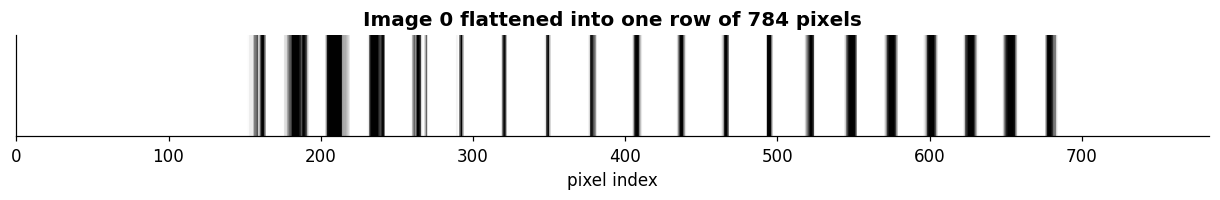

In [ ]:
def to_rows(images):

    return images.reshape(-1, 784) / 255

X_train = to_rows(X_train_img)
X_test = to_rows(X_test_img)

check(X_train.shape == (60000, 784), "X_train: 60,000 rows of 784 pixels", f"X_train has shape {X_train.shape}: one row of 784 per image")
check(X_train.max() == 1.0, "Pixels normalised to 0–1", f"Largest value is {X_train.max()}: it should be exactly 1")
plt.figure(figsize=(14, 1.2)); plt.imshow(X_train[:1], cmap="gray_r", aspect="auto"); plt.yticks([])
plt.title("Image 0 flattened into one row of 784 pixels"); plt.xlabel("pixel index"); plt.show()

---
## 🏗️ 2.4 · Build the digit network &nbsp;<sub>⏱️ ~6 min</sub>
The same kind of network as in 2.2, only bigger.

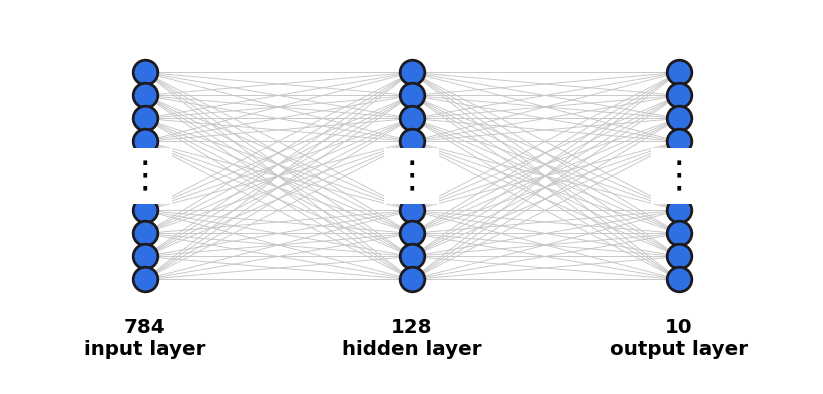

In [ ]:
draw_network([784, 128, 10])

| Layer | Neurons | Role |
|:---|:---|:---|
| 🟦 Input | 784 | one input per pixel (no parameters) |
| 🟦 Hidden | 128 | each neuron is connected to all 784 pixels · ReLU |
| 🟦 Output | 10 | one neuron per digit · an activation that turns the 10 outputs into **probabilities that add up to 1** |

### ✏️ Task 2.4 · Build it with your function
Use `build_network` from Task 2.2. For the output activation, see 📚 [Keras activations](https://keras.io/api/layers/activations/).

✓ 784 inputs → 128 hidden
✓ One output neuron per class
✓ Outputs add up to 1


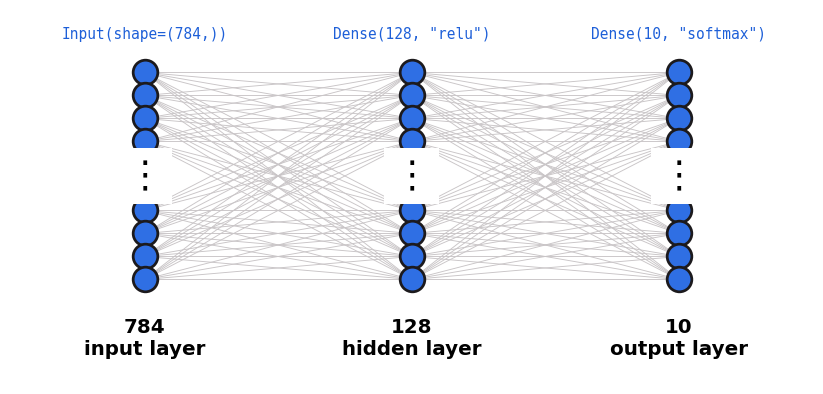

In [ ]:
# inputs per image · number of classes · output activation
model = build_network(784, 128, 10, 'softmax')

check(model.input_shape[-1] == 784 and model.layers[0].units == 128, "784 inputs → 128 hidden", "Inputs: how many pixels per image?")
check(model.output_shape[-1] == len(set(y_train)), "One output neuron per class", "Outputs: how many digits are there?")
check(np.isclose(model(np.random.rand(1, 784)).numpy().sum(), 1, atol=1e-4), "Outputs add up to 1", "Output activation: which one makes probabilities that add up to 1?")
draw_network(model)    # drawn from your code

### ✏️ Task 2.4b · Count the parameters
Each neuron has **one weight per input** plus **one bias**. In the 2 → 5 → 1 network, the hidden layer has 2 × 5 + 5 = **15** parameters. Write the arithmetic, e.g. `2 * 5 + 5`.

In [ ]:
# parameters of the hidden layer
my_hidden_params = 784 * 128 + 128
# parameters of the output layer
my_output_params = 128 * 10 + 10

counts = [l.count_params() for l in model.layers]
check(my_hidden_params == counts[0], f"Hidden layer: {counts[0]:,} parameters", "Hidden layer: inputs × neurons + neurons")
check(my_output_params == counts[1], f"Output layer: {counts[1]:,} parameters", "Output layer: its inputs are the hidden neurons, not the pixels")
print(f"\n🔢 Total: {model.count_params():,} parameters, all random for now.")
print(f"Test accuracy before training: {(model.predict(X_test, verbose=0).argmax(1) == y_test).mean():.0%}  (random guessing ≈ 10%)")

✓ Hidden layer: 100,480 parameters
✓ Output layer: 1,290 parameters

🔢 Total: 101,770 parameters, all random for now.
Test accuracy before training: 8%  (random guessing ≈ 10%)


---
## 🔁 2.5 · Train it &nbsp;<sub>⏱️ ~5 min</sub>
`compile` sets the **loss function** (how wrong a prediction is) and the **optimizer** (how parameters are updated). Both are given.

> 📖 An **epoch** is one pass over the whole training set. `validation_split=0.1` keeps 10% of the training images aside as a **validation set**: never trained on, measured after every epoch. The **test set** stays untouched for the final evaluation.

🧩 **Syntax** (the same supervised call as the hospital model):
```python
model.fit(training_features, training_labels, epochs=3)
```

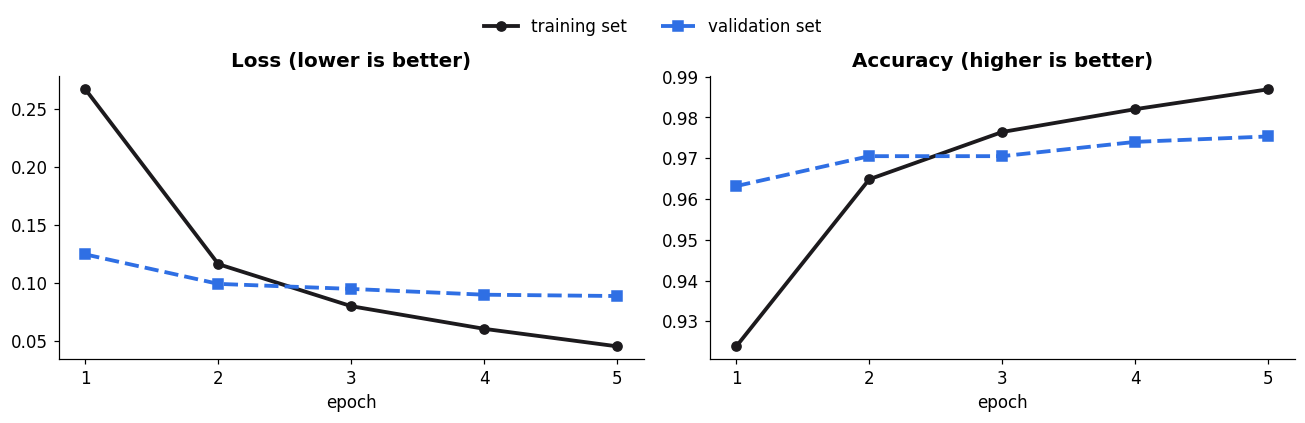

🎯 Test accuracy: 97.3% on 10,000 images never used in training


In [ ]:
# a fresh, untrained copy of your network, so this cell can be re-run from scratch
keras.utils.set_random_seed(42)
model = build_network(784, 128, 10, model.layers[-1].get_config()["activation"])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# training images · training labels · 5 epochs
history = model.fit(X_train, y_train, epochs=5, validation_split=0.1, callbacks=[LiveCurves()], verbose=0)

test_acc = model.evaluate(X_test, y_test, verbose=0)[1]
print(f"🎯 Test accuracy: {test_acc:.1%} on 10,000 images never used in training")

### 💬 Q9 · What did training change?
Test accuracy went from about 10% to about 97%, yet the network has exactly the same layers. What changed inside it, and how?

> The neural network learns from the features and labels. The more epochs the network is trained for, the better it can predict an outcome. Errors are sent backwards through the network and weights are adjusted based on the errors.

---
## 🔬 2.6 · Inspect the predictions &nbsp;<sub>⏱️ ~3 min</sub>
For each image the output layer gives 10 probabilities. The **prediction** is the digit with the highest one.

In [ ]:
probs = model.predict(X_test, verbose=0)      # 10 probabilities per test image
guess = probs.argmax(axis=1)                  # prediction = the most probable digit
wrong = np.where(guess != y_test)[0]
print(f"Misclassified: {len(wrong)} of 10,000 test images.")
interact(prediction_explorer, n=IntSlider(value=0, min=0, max=60, continuous_update=False), errors_only=Checkbox(value=False));

Misclassified: 273 of 10,000 test images.


interactive(children=(IntSlider(value=0, continuous_update=False, description='n', max=60), Checkbox(value=Fal…

### 💬 Q10 · Errors
Tick *errors_only* and look at 5 misclassified images. How many would you have read correctly? Give one example.

> I think most of the images are distinct enough that I would be able to identify them. However, it's reasonable why the model would predict what it did, as I can see why some images may be mistaken for others. Still, there are a few mispredictions that are questionable.

---
## 🧪 2.7 · Hyperparameters and overfitting &nbsp;<sub>⏱️ ~8 min</sub>

> 📖 **Hyperparameters** are settings you choose before training; the network does not learn them. Here: **hidden neurons**, **epochs**, **training set size**.
>
> 📖 **Generalization gap** = training accuracy − validation accuracy. A large gap means the network memorised its training set instead of learning patterns that generalize: **overfitting**.

Each run trains a fresh network on a small training set (so it takes seconds) and evaluates it on 5,000 validation images. 🤔 **Predict the result before each run.**

| Run | `HIDDEN` | `EPOCHS` | `IMAGES` | What changes |
|:---|:---|:---|:---|:---|
| 1 | 0 | 10 | 2000 | no hidden layer: the output layer reads the pixels directly |
| 2 | 128 | 10 | 2000 | add a hidden layer |
| 3 | 512 | 10 | 2000 | 4× the parameters of run 2 |
| 4 | 128 | 40 | 2000 | 4× the epochs of run 2 |
| 5 *(optional)* | 128 | 40 | 20000 | 10× the training data |

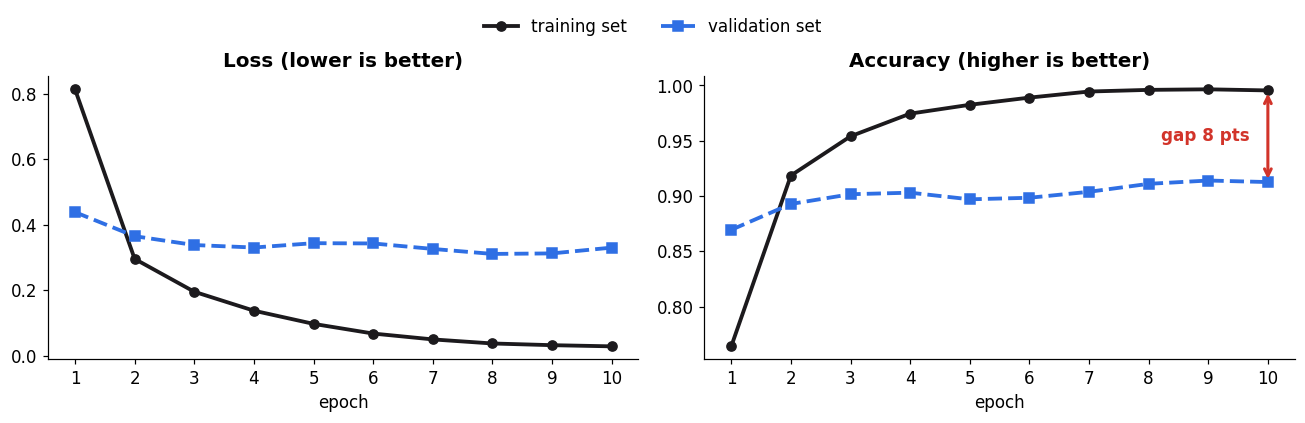

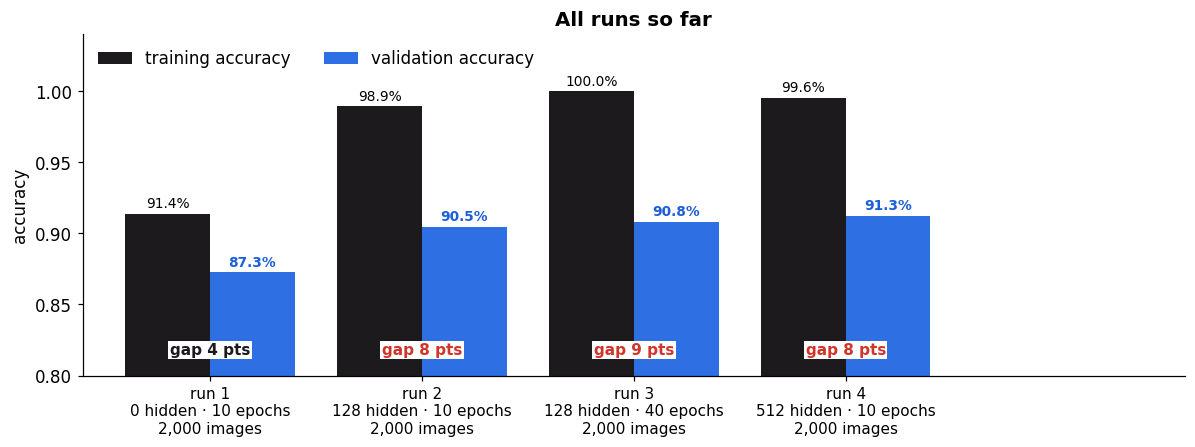

In [ ]:
HIDDEN = 512       # 🧪 edit the three hyperparameters, run, repeat
EPOCHS = 10
IMAGES = 2000
lab_run(HIDDEN, EPOCHS, IMAGES)

### 💬 Q11 · Compare the runs
Use the chart.

**(a)** What did adding a hidden layer do (run 1 → 2)?

**(b)** Did 4× the parameters (run 2 → 3) give a big improvement?

**(c)** What happened in run 4, and what does its generalization gap tell you?
> a. Accuracy increased by the generalization gap also increased.
b. No, negligible improvements were made.
c. In run 4, the generalization gap was the largest, and the validation accuracy actually decreased from run 3. This tells me that the model started to memorize the results rather than predict them.


---
## ↔️ 2.8 · Shift the digits &nbsp;<sub>⏱️ ~3 min · optional, if time</sub>
In class, a 7 shifted 3 pixels to the right changed 168 of its 784 pixel values. 🤔 **Predict:** if every test image is shifted 3 pixels, what will the test accuracy be? Then find an image whose prediction changes.

In [ ]:
interact(shift_explorer, index=IntSlider(value=0, min=0, max=50, continuous_update=False), pixels=IntSlider(value=0, min=0, max=6, continuous_update=False));

interactive(children=(IntSlider(value=0, continuous_update=False, description='index', max=50), IntSlider(valu…

### 💬 Q12 · Why does shifting hurt?
Why does a 3-pixel shift confuse a network that is 97% accurate? Think about what each input neuron receives.

> Each neuron looks at a specific part of the image. If that image shifts, the the neuron looks at a slightly different image, which it's unfamiliar with. This means accuracy decreases.

---
## ✅ End of Part 2
▶️ Run the check. When every line shows ✓ it prints the **second half** of your code phrase.

In [ ]:
#@title ✅ Check Part 2 { display-mode: "form" }
runs = globals().get("lab_runs", [])
part2 = all([
    check("neuron" in globals() and np.isclose(neuron(np.array([0.8, 0.7, 0.3]), np.array([5, 2, 1]), -4), 0.846, atol=0.001),
          "2.1: neuron coded", "2.1: finish Task 2.1"),
    check("build_network" in globals() and [l.units for l in build_network(2, 16, 1, "sigmoid").layers] == [16, 1],
          "2.2: network builder written", "2.2: finish Task 2.2"),
    check("X_train" in globals() and X_train.shape == (60000, 784) and X_train.max() == 1.0, "2.3: images flattened and normalised", "2.3: finish Task 2.3"),
    check(isinstance(globals().get("model"), keras.Model) and model.input_shape[-1] == 784 and model.layers[0].units == 128
          and model.output_shape[-1] == len(set(y_train)) and np.isclose(model(np.random.rand(1, 784)).numpy().sum(), 1, atol=1e-4),
          "2.4: network is 784 → 128 → 10 with probability outputs", "2.4: every check in Task 2.4 must pass"),
    check(isinstance(globals().get("model"), keras.Model) and "my_output_params" in globals() and [my_hidden_params, my_output_params] == [l.count_params() for l in model.layers],
          "2.4b: parameters counted", "2.4b: finish Task 2.4b"),
    check("test_acc" in globals() and test_acc > 0.95, "2.5: test accuracy above 95%", "2.5: train for 5 epochs"),
    check(len(runs) >= 4 and any(r["hidden"] == 0 for r in runs) and any(r["epochs"] >= 40 for r in runs),
          "2.7: runs 1–4 done", "2.7: do runs 1–4 (including HIDDEN = 0 and EPOCHS = 40)"),
])
print()
print("🔑 PART 2 CODE PHRASE:  " + base64.b64decode("aGlkZGVuIG5ldXJvbnMgZGVjaWRlIHdoYXQgdG8gbG9vayBmb3Iu").decode() if part2 else "Fix the ✗ lines above, then run this cell again.")

✓ 2.1: neuron coded
✓ 2.2: network builder written
✓ 2.3: images flattened and normalised
✓ 2.4: network is 784 → 128 → 10 with probability outputs
✓ 2.4b: parameters counted
✓ 2.5: test accuracy above 95%
✓ 2.7: runs 1–4 done

🔑 PART 2 CODE PHRASE:  hidden neurons decide what to look for.


### 📤 Submit
1. **File → Download → Download .ipynb**
2. Submit the file with your **full code phrase** (Part 1's half, then Part 2's half).

<details><summary>🛠️ <b>Troubleshooting</b></summary>

| Error | Usual cause |
|:---|:---|
| `NameError: name 'TODO' is not defined` · `no attribute 'TODO'` | a ✏️ TODO has not been filled in |
| `NameError` for `X_train`, `model`, `neuron`… | the runtime restarted: run the part's ⚙️ setup cell, then the cells after it in order |
| `ValueError … shape` | Task 2.3: each image must become one row of 784 |
| `TypeError: unhashable type: 'list'` | Task A1: the variable is already a list, so don't add a second pair of `[ ]` |
| penguin data does not load | check the internet connection and run the cell again |

</details>

<sub>Data: Breast Cancer Wisconsin (UCI) · Palmer Penguins (Gorman et al. 2014, CC0) · MNIST (LeCun, Cortes & Burges).</sub>